# 📊 Customer Churn Prediction
### Predictive Analytics | Machine Learning | Customer Retention

> An end-to-end machine learning project investigating customer churn,
> identifying influential customer characteristics, and developing a
> predictive classification model.

---

## 01 · Project Overview

Customer churn represents customers discontinuing a service.

**Objective:** Analyze customer behavior and build a machine learning
model to identify customers at risk of leaving.

**Dataset:** Telco Customer Churn  
**Records:** 7,043 customers  
**Target:** Churn (Yes/No)

### Technology Stack
`Python` · `Pandas` · `Scikit-learn` · `Random Forest` ·
`Logistic Regression` · `GridSearchCV`

---

## 02 · Exploratory Data Analysis

### Key Findings

| Customer Segment | Churn Rate |
|---|---:|
| Month-to-month contracts | 42.71% |
| Two-year contracts | 2.83% |
| Fiber-optic internet | 41.89% |
| Electronic check payments | 45.29% |
| Tenure: 0–12 months | 47.44% |
| Tenure: 49–72 months | 9.51% |

**Observations**
- Shorter-tenure customers exhibited higher churn rates.
- Month-to-month contracts were associated with elevated churn.
- Customers who churned paid higher average monthly charges
  ($74.44 vs. $61.27).

These relationships are observational and do not establish causation.

---

## 03 · Machine Learning Pipeline

1. Data cleaning and missing-value handling
2. Numerical feature scaling
3. One-hot encoding of categorical features
4. Stratified 80:20 train-test split
5. Logistic Regression baseline
6. Random Forest classification
7. Five-fold cross-validation
8. Hyperparameter tuning with GridSearchCV
9. Final evaluation on held-out test data

Preprocessing was incorporated into a Scikit-learn Pipeline
to ensure consistency and prevent preprocessing leakage.

---

## 04 · Model Comparison

| Model | Cross-Validation ROC-AUC |
|---|---:|
| Logistic Regression | 0.8457 |
| Random Forest (Default) | 0.8237 |
| Random Forest (Manually Tuned) | 0.8471 |
| Random Forest (GridSearchCV) | **0.8481** |

### Selected Hyperparameters

- Maximum tree depth: 8
- Minimum samples per leaf: 10
- Number of estimators: 200

---

## 05 · Final Model Performance

**Model:** Tuned Random Forest

| Metric | Test Result |
|---|---:|
| Accuracy | 80% |
| Churn Precision | 68% |
| Churn Recall | 51% |
| Churn F1-score | 58% |

The model demonstrated reasonable classification performance,
although identifying more customers who actually churn
remains an important area for improvement.

---

## 06 · Feature Importance

The most influential features included:

1. Contract
2. Tenure
3. InternetService
4. TotalCharges
5. OnlineSecurity

Importance was estimated using permutation importance
on the training data.

---

## 07 · Business Recommendations

- Investigate why month-to-month customers exhibit higher churn.
- Explore retention initiatives for newly acquired customers.
- Examine dissatisfaction factors among fiber-optic subscribers.
- Evaluate targeted customer engagement strategies.

These recommendations are hypotheses for further investigation,
not proven causal interventions.

---

## 08 · Conclusion

Developed an end-to-end customer churn prediction pipeline
using Logistic Regression and Random Forest.

Applied stratified sampling, preprocessing pipelines,
cross-validation, hyperparameter optimization, and
permutation-based feature analysis.

**Best Cross-Validation ROC-AUC: 0.8481**

The project demonstrates a practical application of
predictive modeling to customer retention analytics.


In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns


df=pd.read_csv("/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
print(df["Churn"].unique())
print(df["Churn"].dtype)

['No' 'Yes']
object


In [6]:
df["TotalCharges"]=pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df["TotalCharges"] = df["TotalCharges"].fillna(0)


df["Churn"]=df["Churn"].map({"Yes": 1, "No": 0})

print(df.shape)
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
print("Duplicate customers:", df["customerID"].duplicated().sum())

display(df.head())

(7043, 21)
Missing TotalCharges: 0
Duplicate customers: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


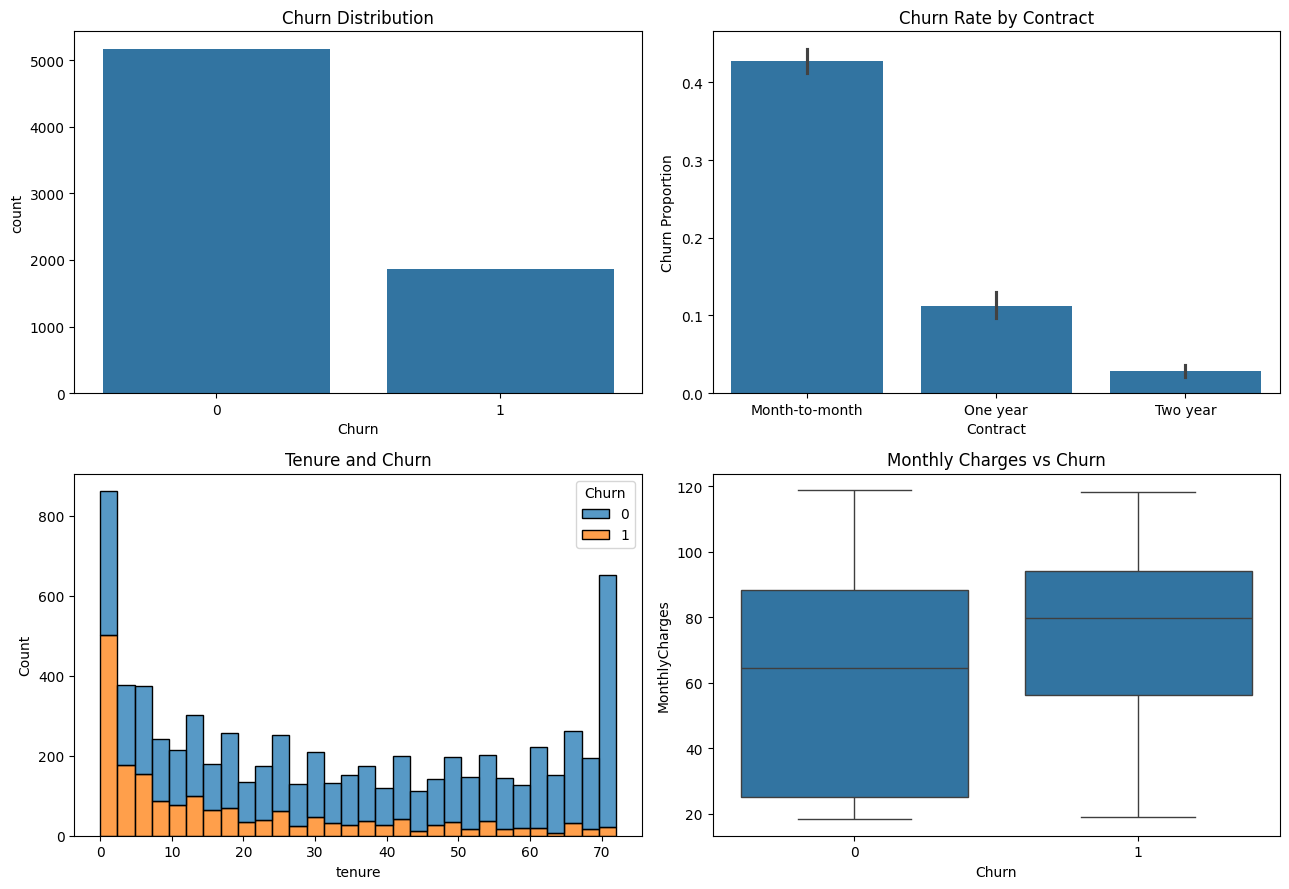


Churn rate by Contract
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Churn rate by InternetService
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64

Churn rate by PaymentMethod
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64


In [7]:
fig, axes = plt.subplots(2,2, figsize=(13,9))
sns.countplot(
    data=df,x="Churn",ax=axes[0,0]
)
axes[0,0].set_title("Churn Distribution")

sns.barplot(
    data=df, x="Contract", y="Churn",
    ax=axes[0,1]
)
axes[0,1].set_title("Churn Rate by Contract")
axes[0,1].set_ylabel("Churn Proportion")

sns.histplot(
    data=df,x="tenure",hue="Churn",
    multiple="stack",bins=30,ax=axes[1,0]
)
axes[1,0].set_title("Tenure and Churn")

sns.boxplot(
    data=df,x="Churn",y="MonthlyCharges",
    ax=axes[1,1]
)
axes[1,1].set_title("Monthly Charges vs Churn")

plt.tight_layout()
plt.show()

for col in ["Contract", "InternetService", "PaymentMethod"]:
    print(f"\nChurn rate by {col}")
    print(
        (df.groupby(col)["Churn"].mean()*100).round(2)
        .sort_values(ascending=False)
    )

In [8]:
df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean","median","min","max"]
).round(2)

,mean,median,min,max
Churn,,,,
0,61.27,64.43,18.25,118.75
1,74.44,79.65,18.85,118.35


In [9]:
df.groupby("Churn")["tenure"].agg(
    ["mean","median","min","max"]
).round(2)

,mean,median,min,max
Churn,,,,
0,37.57,38.0,0,72
1,17.98,10.0,1,72


In [10]:
df["tenure_group"]=pd.cut(
    df["tenure"],
    bins=[-1,12,24,48,72],
    labels=["0-12","13-24","24-48","49-72"]
)

print(
    (df.groupby("tenure_group",observed=True)["Churn"].mean()*100).round(2)
)

tenure_group
0-12     47.44
13-24    28.71
24-48    20.39
49-72     9.51
Name: Churn, dtype: float64


In [11]:
X=df.drop(columns=["customerID","Churn","tenure_group"])
y=df["Churn"]

print(X.shape)
print(y.shape)

(7043, 19)
(7043,)


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(5634, 19)
(1409, 19)


In [13]:
y_train.value_counts(normalize=True)*100

Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64

In [14]:
y_test.value_counts(normalize=True)*100

Churn
0    73.456352
1    26.543648
Name: proportion, dtype: float64

In [15]:
X_train.dtypes

gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
dtype: object

In [16]:
categorical_cols=X_train.select_dtypes(
    include=["object","category"]
).columns.tolist()

numeric_cols=X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print(categorical_cols)
print(numeric_cols)

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [17]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


num_pipeline=Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
cat_pipeline=Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor=ColumnTransformer([
    ("num", num_pipeline, numeric_cols),
    ("cat", cat_pipeline, categorical_cols)
])

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model=Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])
model.fit(X_train, y_train)

print("Model trained successfully")

Model trained successfully


In [19]:
model.score(X_train, y_train)

0.8056443024494143

In [20]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred=model.predict(X_train)

print(confusion_matrix(y_train, y_pred))

print(classification_report(y_train, y_pred))

[[3717  422]
 [ 673  822]]
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      4139
           1       0.66      0.55      0.60      1495

    accuracy                           0.81      5634
   macro avg       0.75      0.72      0.74      5634
weighted avg       0.80      0.81      0.80      5634



In [21]:
y_prob=model.predict_proba(X_train)[:,1]

y_pred_30=(y_prob>=0.30).astype(int)

print(classification_report(y_train,y_pred_30))

              precision    recall  f1-score   support

           0       0.90      0.77      0.83      4139
           1       0.54      0.78      0.64      1495

    accuracy                           0.77      5634
   macro avg       0.72      0.77      0.73      5634
weighted avg       0.81      0.77      0.78      5634



In [22]:
from sklearn.model_selection import cross_val_score

cv_scores=cross_val_score(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="roc_auc"
)

print(cv_scores)
print(cv_scores.mean().round(4))

[0.86360332 0.85326693 0.85101708 0.83620523 0.82430148]
0.8457


In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

rf_model=Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

rf_scores=cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring="roc_auc"
)

print(rf_scores)
print(rf_scores.mean().round(4))

[0.84305374 0.82951626 0.82379065 0.81443782 0.80758716]
0.8237


In [24]:
rf_model.fit(X_train,y_train)
print(rf_model.score(X_train,y_train))
print(model.score(X_train,y_train))

0.9980475683351083
0.8056443024494143


In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

rf_tuned=Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=6,
        min_samples_leaf=10,
        random_state=42
    ))
])
scores_tuned=cross_val_score(
    rf_tuned,
    X_train,
    y_train,
    cv=5,
    scoring="roc_auc"
)

print(scores_tuned.mean().round(4))
rf_tuned.fit(X_train,y_train)
print(rf_tuned.score(X_train,y_train))

0.8471
0.8099041533546326


In [26]:
from sklearn.model_selection import GridSearchCV
param_grid={
    "classifier__max_depth":[4,6,8],
    "classifier__min_samples_leaf":[5,10,20]
}
grid_search=GridSearchCV(
    estimator=rf_tuned,
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid_search.fit(X_train,y_train)
print(grid_search.best_params_)
print(round(grid_search.best_score_, 4))

{'classifier__max_depth': 8, 'classifier__min_samples_leaf': 10}
0.8481


In [27]:
from sklearn.metrics import (
classification_report, confusion_matrix, roc_auc_score
)

best_model=grid_search.best_estimator_
y_test_pred=best_model.predict(X_test)
y_test_prob=best_model.predict_proba(X_test)[:,1]
print(round(roc_auc_score(y_test,y_test_pred)))
print(classification_report(y_test,y_test_pred))

1
              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.68      0.51      0.58       374

    accuracy                           0.80      1409
   macro avg       0.76      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409



In [28]:
from sklearn.inspection import permutation_importance
import pandas as pd

importance=permutation_importance(
    best_model,
    X_train,
    y_train,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42
)

feature_importance=pd.DataFrame({
    "Feature":X_train.columns,
    "Importance":importance.importances_mean
})

print(
    feature_importance
    .sort_values("Importance", ascending=False)
    .head(10)
)

             Feature  Importance
14          Contract    0.046396
4             tenure    0.030412
7    InternetService    0.029506
18      TotalCharges    0.018420
8     OnlineSecurity    0.012979
16     PaymentMethod    0.011557
17    MonthlyCharges    0.010201
11       TechSupport    0.010084
15  PaperlessBilling    0.006626
9       OnlineBackup    0.005396


In [29]:
import joblib
joblib.dump(
    best_model,
    "customer_churn_model.pkl"
)

print("Model saved successfully")

Model saved successfully
